In [1]:
import pandas as pd
import numpy as np

In [2]:
reg_path= "../../data/logistic_datasets/it_infra.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

         cpu     memory     latency  failure_risk
0  84.486991   5.931617   99.255693             0
1  68.566702  22.506828  258.485730             1
2  38.656834  17.473020  490.470188             1
3  29.068811  11.399217  220.877813             0
4  96.807587  19.023641  110.694720             0


In [3]:
import data_logistic_utils as du

du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['cpu', 'memory', 'latency', 'failure_risk']

Data Types:
 cpu             float64
memory          float64
latency         float64
failure_risk      int64
dtype: object

Missing Values:
 cpu             0
memory          0
latency         0
failure_risk    0
dtype: int64

Statistical Summary:
                 cpu        memory       latency  failure_risk
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      54.815619     16.800895    255.103914      0.348800
std       26.143765      8.632289    141.377475      0.476614
min       10.001025      2.000878     10.022019      0.000000
25%       32.146675      9.296606    133.228475      0.000000
50%       54.954264     16.805628    255.875933      0.000000
75%       77.394509     24.311359    376.567592      1.000000
max       99.980754     31.989040    499.972445      1.000000


Converted is not spread equally it is more converted only around 99% is 1 only

In [5]:
target = 'failure_risk'
X = reg_data.drop(columns=[target],axis=1)

y = reg_data[target]

Confusion Matrix:
 [[1287    0]
 [   0  713]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1287
           1       1.00      1.00      1.00       713

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encounter

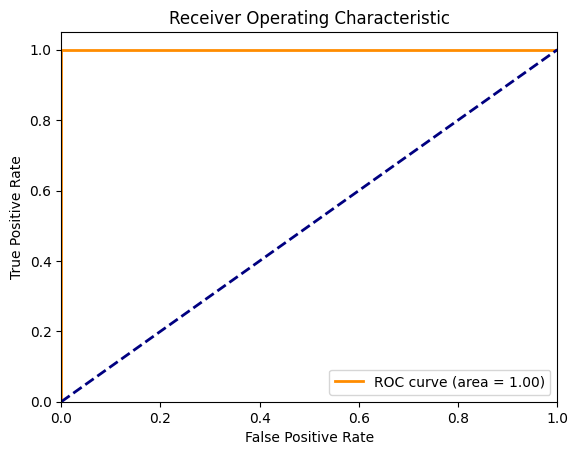

In [6]:
model, y_test, y_pred, X_test = du.logitic_regression(X,y)

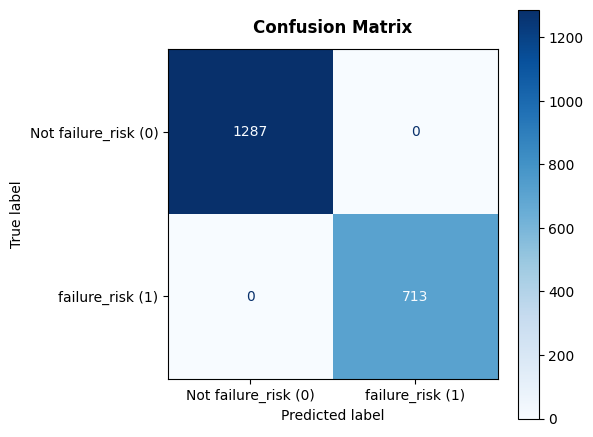

(<Figure size 600x500 with 2 Axes>,
 <Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>)

In [8]:

du.plot_cm(y_test, y_pred, labels=[f"Not {target} (0)", f"{target} (1)"])

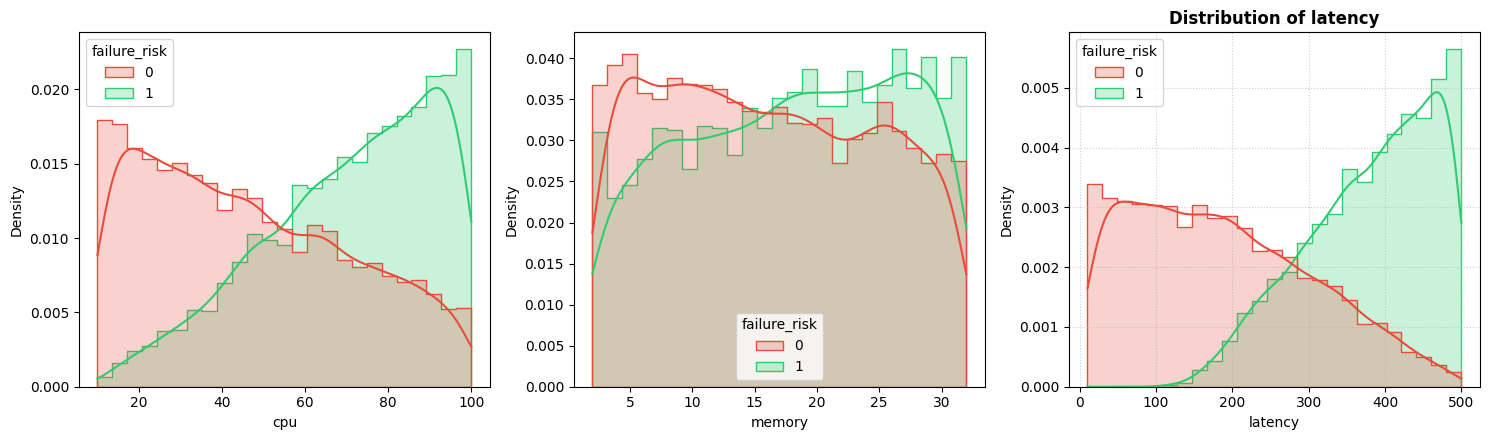

(<Figure size 1500x450 with 3 Axes>,
 array([<Axes: xlabel='cpu', ylabel='Density'>,
        <Axes: xlabel='memory', ylabel='Density'>,
        <Axes: title={'center': 'Distribution of latency'}, xlabel='latency', ylabel='Density'>],
       dtype=object))

In [9]:
import data_logistic_utils as du
du.plot_hist(reg_data,target)